## Digit classification using CNN architecture for MNIST dataset


##### Import Necessary Libraries

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from keras.datasets import mnist
from keras.utils import to_categorical
from keras.models import Sequential
from keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout


#### Loading the MNIST Dataset
The MNIST dataset is a classic dataset of handwritten digits. It contains 60,000 training images and 10,000 testing images. Each image is 28x28 pixels in grayscale.

In [ ]:
(x_train, y_train), (x_test, y_test) = mnist.load_data()

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


#### Displaying an Example Image from the Training Set
In this section, we will display one example image from the training set (x_train) along with its corresponding label (y_train). This helps us visually inspect the data and understand what the images and labels look like.

##### what computer see?

##### Preprocessing the Data
Before feeding the data into the CNN, we need to preprocess it. This involves reshaping the images to include a channel dimension (since Keras expects 4D input for CNNs) and normalizing the pixel values to the range [0, 1]. Additionally, we convert the labels to one-hot encoded vectors.

In [ ]:
# Reshape to include channel dimension and normalize
x_train = x_train.reshape((x_train.shape[0], 28, 28, 1)) / 255
x_test = x_test.reshape((x_test.shape[0], 28, 28, 1)) / 255

# One-hot encode the labels
y_train = to_categorical(y_train)
y_test = to_categorical(y_test)

##### Building the CNN Model
We will build a Convolutional Neural Network (CNN) using Keras’ Sequential API. The model will consist of several layers:

1. Conv2D Layer: Applies convolution operation to the input image.
2. MaxPooling2D Layer: Reduces the spatial dimensions of the image.
3. Flatten Layer: Flattens the 2D output to 1D.
4. Dense Layer: Fully connected layer.
5. Dropout Layer: Prevents overfitting by randomly setting a fraction of input units to 0 during training.

In [ ]:
model = Sequential()
# Conv 1
model.add(Conv2D(32, (3, 3), activation='relu', input_shape=(28, 28, 1)))
model.add(MaxPooling2D((2, 2)))
# Conv 2
model.add(Conv2D(64, (3, 3), activation='relu'))
model.add(MaxPooling2D((2, 2)))

model.add(Flatten())
model.add(Dense(128, activation='relu'))
model.add(Dropout(0.5))
model.add(Dense(10, activation='softmax'))

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


##### Compiling the Model
Next, we compile the model. We use the Adam optimizer, categorical cross-entropy loss function, and accuracy as a metric.

In [ ]:
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

##### Training the Model
We train the model using the training data. We set the number of epochs to 10 and the batch size to 128. We also use 20% of the training data for validation.

In [ ]:
history = model.fit(x_train, y_train, epochs=10, batch_size=128, validation_split=0.2)

Epoch 1/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 44s 113ms/step - accuracy: 0.7612 - loss: 0.7450 - val_accuracy: 0.9778 - val_loss: 0.0738
Epoch 2/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 43s 114ms/step - accuracy: 0.9657 - loss: 0.1146 - val_accuracy: 0.9858 - val_loss: 0.0501
Epoch 3/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 44s 118ms/step - accuracy: 0.9735 - loss: 0.0851 - val_accuracy: 0.9876 - val_loss: 0.0442
Epoch 4/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 41s 109ms/step - accuracy: 0.9803 - loss: 0.0671 - val_accuracy: 0.9886 - val_loss: 0.0388
Epoch 5/10
 94/375 ━━━━━━━━━━━━━━━━━━━━ 25s 91ms/step - accuracy: 0.9832 - loss: 0.0535

KeyboardInterrupt: 

##### Evaluating the Model
After training, we evaluate the model on the test data to see how well it performs on unseen data.

In [ ]:
test_loss, test_acc = model.evaluate(x_test, y_test)
print(f'Test accuracy: {test_acc}')

313/313 [==============================] - 1s 2ms/step - loss: 0.0266 - accuracy: 0.9910
Test accuracy: 0.9909999966621399


##### Plotting Training History
Finally, we plot the training and validation accuracy over the epochs to visualize the model’s performance.

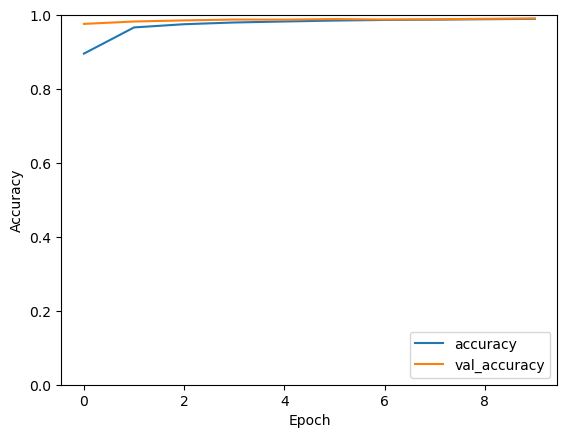

In [ ]:
plt.plot(history.history['accuracy'], label='accuracy')
plt.plot(history.history['val_accuracy'], label = 'val_accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.ylim([0, 1])
plt.legend(loc='lower right')
plt.show()

#### create a confusion matrix plot

313/313 [==============================] - 1s 2ms/step


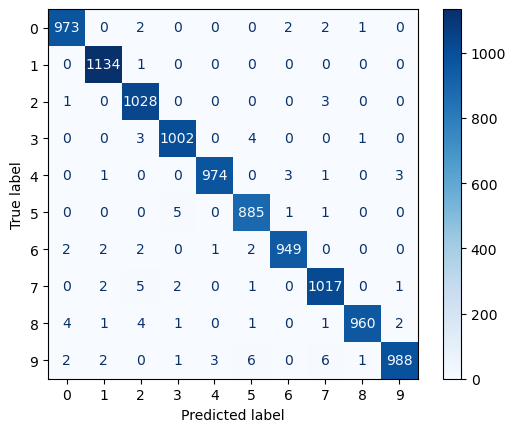

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Assuming x_test and y_test are your test data and true labels
y_pred = model.predict(x_test)
y_pred_classes = np.argmax(y_pred, axis=1)
y_true = np.argmax(y_test, axis=1)

# Compute confusion matrix
cm = confusion_matrix(y_true, y_pred_classes)

# Plot confusion matrix
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap=plt.cm.Blues)
plt.show()

### Building the CNN Model with Additional Convolutional Layers

In [ ]:
from keras.models import Sequential
from keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout

# Building the CNN model
model = Sequential()

# First convolutional layer
model.add(Conv2D(32, (3, 3), activation='relu', input_shape=(28, 28, 1)))
model.add(MaxPooling2D((2, 2)))

# Second convolutional layer
model.add(Conv2D(64, (3, 3), activation='relu'))
model.add(MaxPooling2D((2, 2)))

# Third convolutional layer (additional)
model.add(Conv2D(128, (3, 3), activation='relu'))
model.add(MaxPooling2D((2, 2)))

# Flattening the output
model.add(Flatten())

# Fully connected layer
model.add(Dense(128, activation='relu'))
model.add(Dropout(0.5))

# Output layer
model.add(Dense(10, activation='softmax'))

##### Explanation of Each Layer
1. First Convolutional Layer:
    1. Conv2D(32, (3, 3), activation=‘relu’, input_shape=(28, 28, 1)): This layer applies 32 filters of size 3x3 to the input image. The activation function used is ReLU (Rectified Linear Unit), which introduces non-linearity to the model. The input_shape parameter specifies the shape of the input image (28x28 pixels with 1 channel for grayscale).
    1. MaxPooling2D((2, 2)): This layer performs max pooling with a 2x2 filter, reducing the spatial dimensions of the image by half.
1. Second Convolutional Layer:
    1. Conv2D(64, (3, 3), activation=‘relu’): This layer applies 64 filters of size 3x3 to the output of the previous layer. The ReLU activation function is used again.
    1. MaxPooling2D((2, 2)): Another max pooling layer to further reduce the spatial dimensions.
1. Third Convolutional Layer (Additional):
    1. Conv2D(128, (3, 3), activation=‘relu’): This additional layer applies 128 filters of size 3x3. Adding more filters helps the model learn more complex features.
    1. MaxPooling2D((2, 2)): Max pooling layer to reduce the spatial dimensions.
1. Flattening the Output:
    1. Flatten(): This layer flattens the 2D output of the convolutional layers into a 1D vector, which can be fed into the fully connected layers.
1. Fully Connected Layer:
    1. Dense(128, activation=‘relu’): This dense layer has 128 units and uses the ReLU activation function. It is fully connected to the flattened output from the previous layer.
    1. Dropout(0.5): This dropout layer randomly sets 50% of the input units to 0 during training to prevent overfitting.
1. Output Layer:
    1. Dense(10, activation=‘softmax’): The final dense layer has 10 units (one for each digit class) and uses the softmax activation function to output a probability distribution over the 10 classes.

This enhanced CNN model with additional convolutional layers should be able to learn more complex features from the MNIST dataset, potentially improving its performance on the digit classification task.